## 06 — Downsampling Sensitivity Analysis
Tests whether the 128×128 spatial resolution used in feature extraction is sufficient,
or whether finer resolution would materially change the features and their relationship with AOD.

For a stratified sample of 100 images, four feature groups are extracted at 64, 96, 128, and 160 px
and compared against native resolution (~500×500 px). Metrics:
1. Spearman r of each feature value vs native (feature preservation)
2. Fraction of features with r > 0.99 vs native (fidelity threshold)
3. Per-category breakdown (band means, band stds, spectral indices, GLCM)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import tifffile
from pathlib import Path
from scipy.stats import spearmanr
from skimage.feature import graycomatrix, graycoprops

ROOT      = Path('D:/Regional-Scale-AOD-Estimation')
SPLITS    = ROOT / 'feature_engineering/splits'
OUT       = ROOT / 'feature_engineering/features_analysis/sensitivity_analysis_downsampling'
OUT.mkdir(parents=True, exist_ok=True)

TARGET      = 'AOD_550nm'
RESOLUTIONS = [64, 96, 128, 160]   # native is the reference
N_SAMPLE    = 100
SEED        = 42

MIN_COVERAGE  = 0.90
CIRRUS_THRESH = 300
GLCM_LEVELS   = 64

In [2]:
df = pd.read_csv(SPLITS / 'stratified_train.csv')
df['aod_q'] = pd.qcut(df[TARGET], q=4, labels=False)
groups = [g.sample(min(len(g), N_SAMPLE // 4), random_state=SEED)
          for _, g in df.groupby('aod_q', group_keys=False)]
sample = pd.concat(groups).sample(frac=1, random_state=SEED).reset_index(drop=True)
print(f'Sample: {len(sample)} images | AOD range [{sample[TARGET].min():.3f}, {sample[TARGET].max():.3f}]')

Sample: 100 images | AOD range [0.028, 0.817]


In [3]:
def load_and_filter(img_path):
    """Load native GeoTIFF, apply coverage + cirrus filters. Returns (H,W,13) float32 or None."""
    raw = tifffile.imread(str(img_path)).astype(np.float32)
    if raw.ndim == 3 and raw.shape[0] == 13:
        raw = raw.transpose(1, 2, 0)
    valid = (raw > 0) & (raw <= 10000)
    if valid.mean(axis=(0, 1)).min() < MIN_COVERAGE:
        return None
    if np.percentile(raw[:, :, 10], 95) > CIRRUS_THRESH:
        return None
    return raw


def resize_bands(img_hw13, size):
    """Resize each band independently with INTER_AREA (cv2 only supports ≤4 channels)."""
    return np.stack(
        [cv2.resize(img_hw13[:, :, b], (size, size), interpolation=cv2.INTER_AREA)
         for b in range(img_hw13.shape[2])],
        axis=2,
    )


def extract_features(img_hw13, size=None):
    """
    Extract feature subset from a filtered (H,W,13) float32 DN array.
    If size is given, downsample to (size, size) first using INTER_AREA.
    """
    img  = resize_bands(img_hw13, size) if size else img_hw13
    refl = img / 10000.0
    feats = {}

    # Band means and stds (13 bands each)
    for b in range(13):
        feats[f'B{b:02d}_mean'] = float(np.mean(refl[:, :, b]))
        feats[f'B{b:02d}_std']  = float(np.std(refl[:, :, b]))

    # NDVI (NIR=B08 idx7, Red=B04 idx3)
    nir, red = refl[:, :, 7], refl[:, :, 3]
    denom = nir + red
    ndvi = np.where(np.abs(denom) > 1e-6, (nir - red) / denom, 0.0)
    feats['ndvi_mean'] = float(np.mean(ndvi))
    feats['ndvi_std']  = float(np.std(ndvi))

    # B01 / B11 normalised difference (aerosol-sensitive band pair)
    b01, b11 = refl[:, :, 0], refl[:, :, 11]
    denom = b01 + b11
    nd = np.where(np.abs(denom) > 1e-6, (b01 - b11) / denom, 0.0)
    feats['nd_B01_B11_mean'] = float(np.mean(nd))
    feats['nd_B01_B11_std']  = float(np.std(nd))

    # GLCM on B02 reflectance clipped to [0, 0.5] — same scale as main pipeline
    b02 = np.clip(refl[:, :, 1], 0, 0.5)
    b02_uint = (b02 / 0.5 * (GLCM_LEVELS - 1)).astype(np.uint8)
    glcm = graycomatrix(
        b02_uint, distances=[1],
        angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4],
        levels=GLCM_LEVELS, symmetric=True, normed=True,
    )
    for prop in ('contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation'):
        feats[f'glcm_{prop}'] = float(graycoprops(glcm, prop).mean())

    return feats

In [4]:
records = []
skipped = 0

for img_id, row in sample.iterrows():
    img_path = ROOT / row['image_path']
    try:
        raw = load_and_filter(img_path)
    except Exception:
        skipped += 1
        continue
    if raw is None:
        skipped += 1
        continue

    native_h = raw.shape[0]
    res_list = [('native', None)] + [(str(r), r) for r in RESOLUTIONS]

    for res_label, size in res_list:
        feats = extract_features(raw, size=size)
        rec   = {'image_id': img_id, 'aod': row[TARGET],
                 'resolution': res_label, 'native_h': native_h}
        rec.update(feats)
        records.append(rec)

df_all  = pd.DataFrame(records)
n_valid = (df_all['resolution'] == 'native').sum()
print(f'Valid images: {n_valid} | Skipped: {skipped}')
print(f'Median native size: {int(df_all[df_all.resolution == "native"]["native_h"].median())} px')
print(df_all['resolution'].value_counts())

C:\Users\LOQ\AppData\Local\Temp\ipykernel_17056\3644617091.py:40: RuntimeWarning: invalid value encountered in divide
  ndvi = np.where(np.abs(denom) > 1e-6, (nir - red) / denom, 0.0)


Valid images: 78 | Skipped: 22
Median native size: 500 px
resolution
native    78
64        78
96        78
128       78
160       78
Name: count, dtype: int64


In [5]:
feat_cols = [c for c in df_all.columns if c not in ('image_id', 'aod', 'resolution', 'native_h')]

native_df = (
    df_all[df_all['resolution'] == 'native']
    [['image_id', 'aod'] + feat_cols]
    .set_index('image_id')
    .rename(columns={f: f + '_nat' for f in feat_cols})
)

results = []
for res in RESOLUTIONS:
    res_sub = (
        df_all[df_all['resolution'] == str(res)]
        [['image_id'] + feat_cols]
        .set_index('image_id')
        .rename(columns={f: f + '_res' for f in feat_cols})
    )
    merged = native_df.join(res_sub).dropna()

    for f in feat_cols:
        r_val, _     = spearmanr(merged[f + '_nat'], merged[f + '_res'])
        r_aod_nat, _ = spearmanr(merged[f + '_nat'], merged['aod'])
        r_aod_res, _ = spearmanr(merged[f + '_res'], merged['aod'])
        results.append({
            'resolution':   res,
            'feature':      f,
            'r_vs_native':  float(r_val),
            'r_aod_native': float(r_aod_nat),
            'r_aod_res':    float(r_aod_res),
            'delta_r_aod':  abs(float(r_aod_res)) - abs(float(r_aod_nat)),
        })

results_df = pd.DataFrame(results)

agg = (
    results_df.groupby('resolution')
    .agg(
        median_r_vs_native   =('r_vs_native', 'median'),
        pct_r_gt_099         =('r_vs_native', lambda x: (x > 0.99).mean() * 100),
        mean_abs_delta_r_aod =('delta_r_aod', lambda x: x.abs().mean()),
    )
    .reset_index()
    .sort_values('resolution')
)

print('Resolution sensitivity summary:')
print(agg.to_string(index=False))

Resolution sensitivity summary:
 resolution  median_r_vs_native  pct_r_gt_099  mean_abs_delta_r_aod
         64            0.996459     74.285714              0.013896
         96            0.998204     77.142857              0.010045
        128            0.998887     77.142857              0.007596
        160            0.999140     80.000000              0.007314


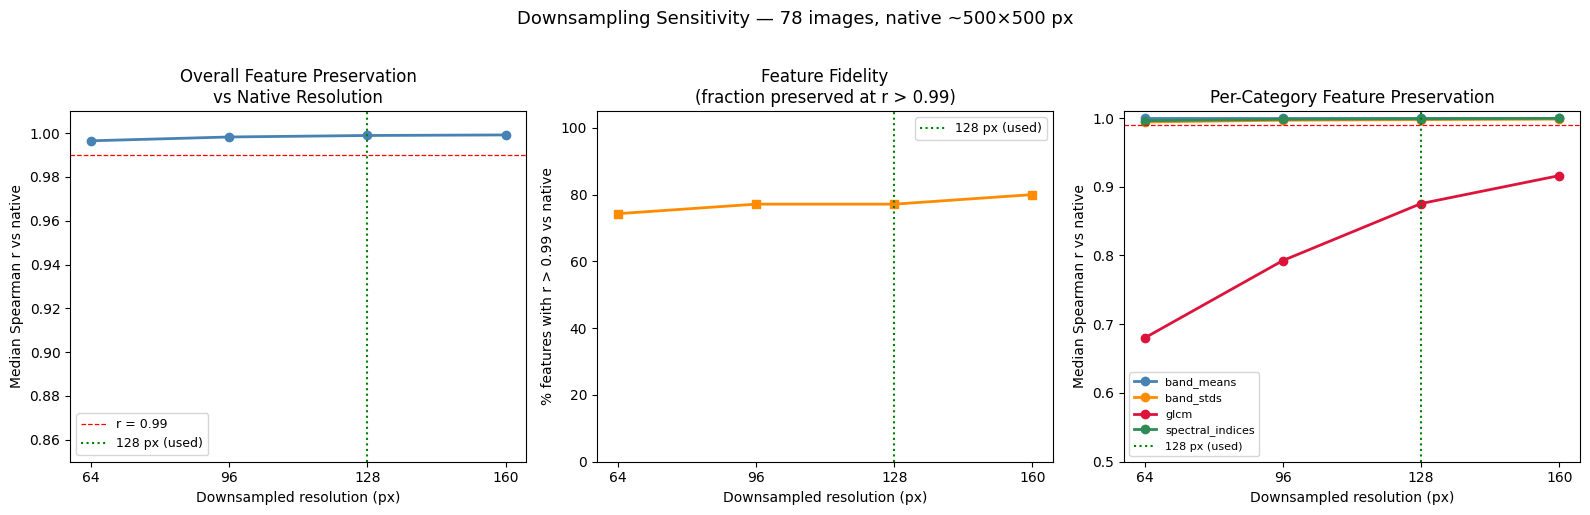

Saved: sensitivity_analysis.png


In [6]:
# Assign each feature to a display category
def feature_category(f):
    if f.endswith('_mean') and f.startswith('B'):
        return 'band_means'
    if f.endswith('_std') and f.startswith('B'):
        return 'band_stds'
    if f.startswith('glcm_'):
        return 'glcm'
    return 'spectral_indices'

results_df['category'] = results_df['feature'].map(feature_category)

cat_agg = (
    results_df.groupby(['resolution', 'category'])['r_vs_native']
    .median()
    .reset_index()
)

median_native_h = int(df_all[df_all.resolution == 'native']['native_h'].median())
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Panel 1: median r vs native across all features
axes[0].plot(agg['resolution'], agg['median_r_vs_native'], 'o-', color='steelblue', linewidth=2)
axes[0].axhline(0.99, color='red', linestyle='--', linewidth=0.9, label='r = 0.99')
axes[0].axvline(128, color='green', linestyle=':', linewidth=1.5, label='128 px (used)')
axes[0].set_xlabel('Downsampled resolution (px)')
axes[0].set_ylabel('Median Spearman r vs native')
axes[0].set_title('Overall Feature Preservation\nvs Native Resolution')
axes[0].legend(fontsize=9)
axes[0].set_ylim(0.85, 1.01)
axes[0].set_xticks(RESOLUTIONS)

# Panel 2: % of features with r > 0.99
axes[1].plot(agg['resolution'], agg['pct_r_gt_099'], 's-', color='darkorange', linewidth=2)
axes[1].axvline(128, color='green', linestyle=':', linewidth=1.5, label='128 px (used)')
axes[1].set_xlabel('Downsampled resolution (px)')
axes[1].set_ylabel('% features with r > 0.99 vs native')
axes[1].set_title('Feature Fidelity\n(fraction preserved at r > 0.99)')
axes[1].legend(fontsize=9)
axes[1].set_ylim(0, 105)
axes[1].set_xticks(RESOLUTIONS)

# Panel 3: per-category breakdown
cat_colors = {'band_means': 'steelblue', 'band_stds': 'darkorange',
              'spectral_indices': 'seagreen', 'glcm': 'crimson'}
for cat, grp in cat_agg.groupby('category'):
    grp = grp.sort_values('resolution')
    axes[2].plot(grp['resolution'], grp['r_vs_native'], 'o-',
                 label=cat, color=cat_colors.get(cat), linewidth=2)
axes[2].axhline(0.99, color='red', linestyle='--', linewidth=0.9)
axes[2].axvline(128, color='green', linestyle=':', linewidth=1.5, label='128 px (used)')
axes[2].set_xlabel('Downsampled resolution (px)')
axes[2].set_ylabel('Median Spearman r vs native')
axes[2].set_title('Per-Category Feature Preservation')
axes[2].legend(fontsize=8)
axes[2].set_ylim(0.5, 1.01)
axes[2].set_xticks(RESOLUTIONS)

plt.suptitle(
    f'Downsampling Sensitivity — {n_valid} images, '
    f'native ~{median_native_h}×{median_native_h} px',
    y=1.02, fontsize=13,
)
plt.tight_layout()
plt.savefig(OUT / 'sensitivity_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: sensitivity_analysis.png')

In [ ]:
agg.to_csv(OUT / 'resolution_summary.csv', index=False)
results_df.to_csv(OUT / 'per_feature_results.csv', index=False)
print('Saved: resolution_summary.csv, per_feature_results.csv')
print(agg.to_string(index=False))

Saved: resolution_summary.csv, per_feature_results.csv
 resolution  median_r_vs_native  pct_r_gt_099  mean_abs_delta_r_aod
         64            0.996459     74.285714              0.013896
         96            0.998204     77.142857              0.010045
        128            0.998887     77.142857              0.007596
        160            0.999140     80.000000              0.007314
